# Classical Optimization: Regression and Classification

We compare four update rules on the **same empirical risk**, built from 600
noisy observations with two correlated, differently scaled features. This is
a convex regression problem, so we can calculate its least-squares minimizer
and see how each optimizer approaches it. The point is the path and the
changing step scale, not a ranking: each method has a declared learning rate.

We then repeat the comparison on 64-feature **multinomial logistic regression**
with real handwritten-digit data. Both objectives are convex in their
coefficients. Run the cells in order; the digits CSV downloads automatically
when opened in Colab.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 26512
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

n = 600
angle = np.pi / 6
Q = np.array([[np.cos(angle), -np.sin(angle)],
              [np.sin(angle),  np.cos(angle)]])
A = Q @ np.diag([7.0, 0.7]) @ Q.T
X_np = rng.normal(size=(n, 2)) @ A
true_w = np.array([1.0, -1.0])
y_np = X_np @ true_w + rng.normal(scale=0.5, size=n)
X = torch.tensor(X_np, dtype=torch.float64)
y = torch.tensor(y_np, dtype=torch.float64)
H = X_np.T @ X_np / n
w_star = np.linalg.solve(H, X_np.T @ y_np / n)
print('X shape:', X.shape, 'Hessian eigenvalues:', np.round(np.linalg.eigvalsh(H), 2))
print('Hessian condition number:', round(np.linalg.cond(H), 1))
print('least-squares minimizer:', np.round(w_star, 3))

X shape: torch.Size([600, 2]) Hessian eigenvalues: [ 0.49 47.7 ]
Hessian condition number: 96.7
least-squares minimizer: [ 0.986 -0.976]


## The objective and four update rules

For $w\in\mathbb R^2$, the risk is

$$R(w)=\frac{1}{2n}\sum_{i=1}^n(x_i^\top w-y_i)^2.$$

Its Hessian is $X^\top X/n$. Unequal Hessian eigenvalues create a narrow
valley, so one scalar SGD step size must respect the steep direction.
AdaGrad sums squared gradients by coordinate; RMSProp discounts old squares;
Adam combines a moving gradient average with a discounted squared average.
All runs start at the same $w_0$ and use full-batch gradients, so the
differences come from the update rules rather than data order.

In [2]:
START = torch.tensor([3.0, 2.0], dtype=torch.float64)
STEPS = 400
SETTINGS = {
    'SGD': 0.018,
    'AdaGrad': 0.25,
    'RMSProp': 0.045,
    'Adam': 0.075,
}

def make_optimizer(name, w):
    lr = SETTINGS[name]
    if name == 'SGD':
        return torch.optim.SGD([w], lr=lr)
    if name == 'AdaGrad':
        return torch.optim.Adagrad([w], lr=lr)
    if name == 'RMSProp':
        return torch.optim.RMSprop([w], lr=lr, alpha=0.99)
    return torch.optim.Adam([w], lr=lr)

def risk(w):
    return 0.5 * ((X @ w - y) ** 2).mean()

def run_optimizer(name):
    w = torch.nn.Parameter(START.clone())
    optimizer = make_optimizer(name, w)
    path = [w.detach().numpy().copy()]
    losses = [float(risk(w).detach())]
    scales = []
    for _ in range(STEPS):
        optimizer.zero_grad()
        risk(w).backward()
        optimizer.step()
        path.append(w.detach().numpy().copy())
        losses.append(float(risk(w).detach()))
        state = optimizer.state[w]
        if name == 'AdaGrad':
            scales.append((SETTINGS[name] / (state['sum'].sqrt() + 1e-10)).numpy().copy())
        elif name == 'RMSProp':
            scales.append((SETTINGS[name] / (state['square_avg'].sqrt() + 1e-8)).numpy().copy())
    return np.array(path), np.array(losses), np.array(scales)

results = {name: run_optimizer(name) for name in SETTINGS}
minimum = float(risk(torch.tensor(w_star)))
display(pd.DataFrame([
    {'method': name, 'learning rate': SETTINGS[name],
     'final excess risk': loss[-1] - minimum,
     'distance to minimizer': np.linalg.norm(path[-1] - w_star)}
    for name, (path, loss, _) in results.items()
]).round(5))

,method,learning rate,final excess risk,distance to minimizer
0,SGD,0.018,0.00048,0.04395
1,AdaGrad,0.250,0.08815,0.59770
2,RMSProp,0.045,0.00570,0.15205
3,Adam,0.075,0.03252,0.36304


## Paths through the same landscape

The left panel draws contours of the empirical risk and each optimizer's
coefficient path. The right panel shows excess risk
$R(w_t)-R(w^*)$ against optimizer steps. The black star is the exact
least-squares minimizer. Compare the *shape* of the paths as well as the
endpoints; distinct learning rates mean this is an illustration, not a
controlled speed contest.

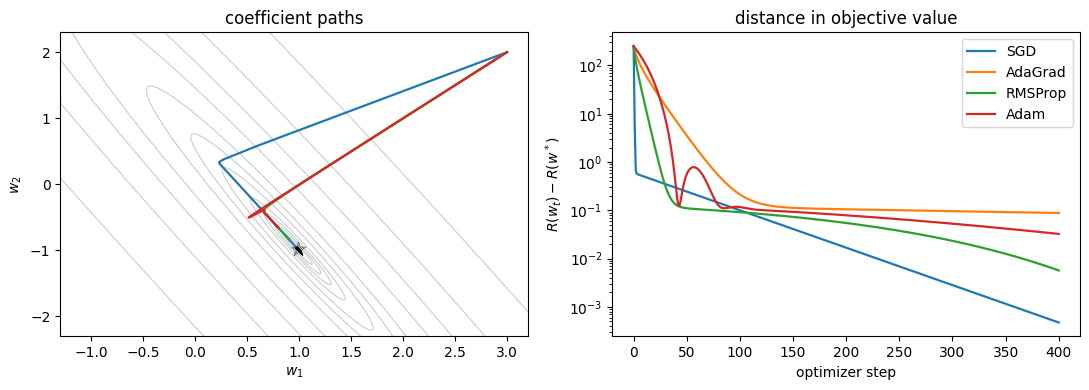

In [3]:
u = np.linspace(-1.3, 3.2, 170)
v = np.linspace(-2.3, 2.3, 170)
U, V = np.meshgrid(u, v)
grid = np.stack([U.ravel(), V.ravel()], axis=1)
excess = 0.5 * np.einsum('ni,ij,nj->n', grid-w_star, H, grid-w_star).reshape(U.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].contour(U, V, excess, levels=[.02,.05,.1,.2,.5,1,2,5,10,20,50],
                colors='0.8', linewidths=.8)
for name, (path, loss, _) in results.items():
    axes[0].plot(path[:,0], path[:,1], label=name, lw=1.6)
    axes[1].semilogy(np.maximum(loss-minimum, 1e-12), label=name, lw=1.6)
axes[0].scatter([w_star[0]], [w_star[1]], marker='*', color='black', s=100)
axes[0].set(xlabel='$w_1$', ylabel='$w_2$', title='coefficient paths',
            xlim=(u.min(),u.max()), ylim=(v.min(),v.max()))
axes[1].set(xlabel='optimizer step', ylabel='$R(w_t)-R(w^*)$',
            title='distance in objective value')
axes[1].legend()
fig.tight_layout()
plt.show()

## Why AdaGrad can slow down

The effective coordinate scale in AdaGrad is
$\eta/(\sqrt{v_{t,j}}+\varepsilon)$, where $v_{t,j}$ is a **sum** of
squared gradients. RMSProp uses a discounted average instead. The curves
below show the two scales on this run. They depend on the method's own
gradient path, so compare each curve over time rather than treating the
values across methods as directly interchangeable.

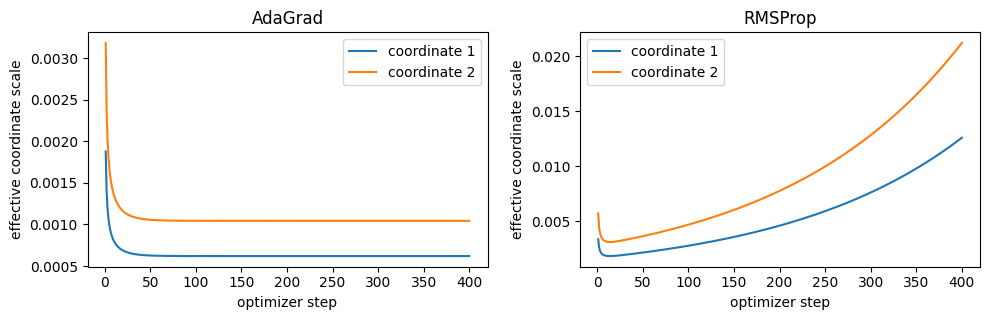

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=False)
for ax, name in zip(axes, ['AdaGrad', 'RMSProp']):
    scales = results[name][2]
    for j in range(2):
        ax.plot(np.arange(1, len(scales)+1), scales[:,j], label=f'coordinate {j+1}')
    ax.set(xlabel='optimizer step', ylabel='effective coordinate scale',
           title=name)
    ax.legend()
fig.tight_layout()
plt.show()

**Takeaway.** Coordinate-wise scaling can
change the path through a narrow valley. AdaGrad's accumulated squared
gradients make its scales nonincreasing; RMSProp's discounted history can
adapt when the gradient pattern changes. Muon is designed for hidden **weight
matrices** in neural networks, so the next notebook compares it on that
setting rather than applying it to this two-coordinate vector.

## A second convex problem: digit classification

Least squares made the two-dimensional paths visible. Now fit a linear
ten-class classifier to 8-by-8 digit images. Its cross-entropy is convex in
the 64-by-10 coefficient matrix and bias vector. We use a stratified
training/validation split, start every method from zero coefficients, and
take full-batch steps. Unlike the first plot, here we can measure held-out
classification accuracy. The next notebook replaces this linear classifier
with a two-hidden-layer network on the **same data**.

In [5]:
from pathlib import Path
import urllib.request
from sklearn.model_selection import train_test_split
from torch import nn

csv = Path('SklearnDigits.csv')
if not csv.exists():
    url = ('https://raw.githubusercontent.com/ZhuoranYang/sds265-fall26/'
           'main/demos/12-neural-optimization/SklearnDigits.csv')
    urllib.request.urlretrieve(url, csv)
frame = pd.read_csv(csv)
X_all = frame.drop(columns='target').to_numpy(np.float32) / 16.0
y_all = frame['target'].to_numpy(np.int64)
train_idx, valid_idx = train_test_split(
    np.arange(len(y_all)), test_size=0.25, random_state=SEED,
    stratify=y_all
)
X_tr = torch.tensor(X_all[train_idx])
y_tr = torch.tensor(y_all[train_idx])
X_va = torch.tensor(X_all[valid_idx])
y_va = torch.tensor(y_all[valid_idx])
print('train:', tuple(X_tr.shape), 'validation:', tuple(X_va.shape))

LOGISTIC_RATES = {'SGD': 0.30, 'AdaGrad': 0.10,
                  'RMSProp': 0.010, 'Adam': 0.010}
LOGISTIC_STEPS = 250

def logistic_run(name):
    model = nn.Linear(64, 10)
    nn.init.zeros_(model.weight)
    nn.init.zeros_(model.bias)
    lr = LOGISTIC_RATES[name]
    if name == 'SGD':
        opt = torch.optim.SGD(model.parameters(), lr=lr)
    elif name == 'AdaGrad':
        opt = torch.optim.Adagrad(model.parameters(), lr=lr)
    elif name == 'RMSProp':
        opt = torch.optim.RMSprop(model.parameters(), lr=lr)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    rows = []
    for step in range(LOGISTIC_STEPS + 1):
        with torch.no_grad():
            logits = model(X_va)
            rows.append({'method': name, 'step': step,
                         'validation loss': float(nn.functional.cross_entropy(logits, y_va)),
                         'validation accuracy': float((logits.argmax(1) == y_va).float().mean())})
        if step == LOGISTIC_STEPS:
            break
        opt.zero_grad()
        nn.functional.cross_entropy(model(X_tr), y_tr).backward()
        opt.step()
    return pd.DataFrame(rows)

logistic_history = pd.concat([logistic_run(name) for name in LOGISTIC_RATES],
                             ignore_index=True)
display(logistic_history.groupby('method', sort=False).tail(1)[
    ['method', 'validation loss', 'validation accuracy']
].round(3))

train: (1347, 64) validation: (450, 64)


,method,validation loss,validation accuracy
250,SGD,0.329,0.947
501,AdaGrad,0.167,0.960
752,RMSProp,0.130,0.973
1003,Adam,0.181,0.951


## Compare validation curves

All four methods optimize the same linear classifier and use the same
training examples. Their learning rates are listed in the code. These
particular rates make a useful comparison of training paths; they are not
equally tuned hyperparameters. The held-out curves show both progress and
any late changes in prediction quality.

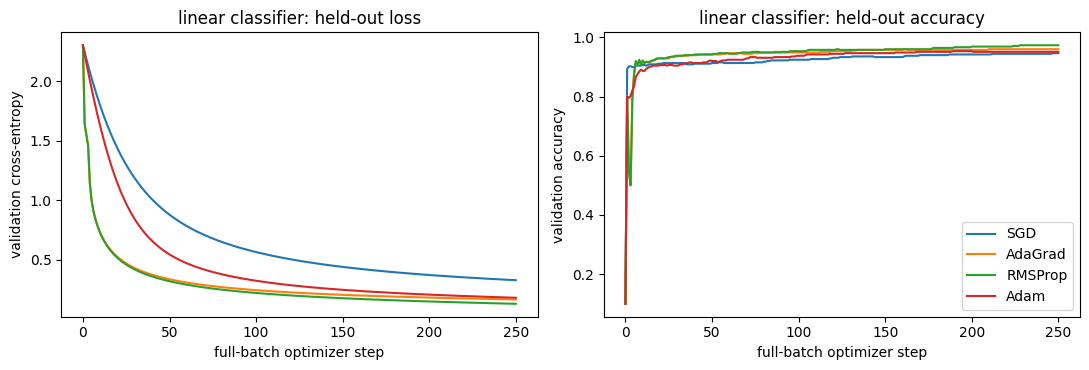

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, group in logistic_history.groupby('method', sort=False):
    axes[0].plot(group.step, group['validation loss'], label=name)
    axes[1].plot(group.step, group['validation accuracy'], label=name)
axes[0].set(xlabel='full-batch optimizer step', ylabel='validation cross-entropy',
            title='linear classifier: held-out loss')
axes[1].set(xlabel='full-batch optimizer step', ylabel='validation accuracy',
            title='linear classifier: held-out accuracy')
axes[1].legend()
fig.tight_layout()
plt.show()